In [36]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [37]:
df = pd.read_csv(r'/Users/aaryapatil/Desktop/esssssay/Optimizing-Household-Electricity-through-Machine-Learning/Datasets/electricity_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df[df['Date'].dt.year == 2021]
df.reset_index(drop=True, inplace=True)

In [38]:
df.head(3)

,Date,Total_Consumption
0,2021-01-01,7.7
1,2021-01-02,8.5
2,2021-01-03,7.7


In [39]:
df.tail()

,Date,Total_Consumption
198,2021-07-26,26.1
199,2021-07-27,24.3
200,2021-07-28,23.4
201,2021-07-29,16.8
202,2021-07-30,16.8


In [40]:
df.shape

(203, 2)

In [41]:
import math
import statsmodels.api as sm
import statsmodels.tsa.api as smt
from sklearn.metrics import mean_squared_error
from matplotlib import pyplot
import matplotlib.pyplot as plt

actual_vals = df.Total_Consumption.values
actual_log = np.log10(actual_vals)

train, test = actual_vals[0:-80], actual_vals[-80:]
train_log, test_log = np.log10(train), np.log10(test)
my_order = (1, 1, 1)
my_seasonal_order = (1, 1, 1, 7)

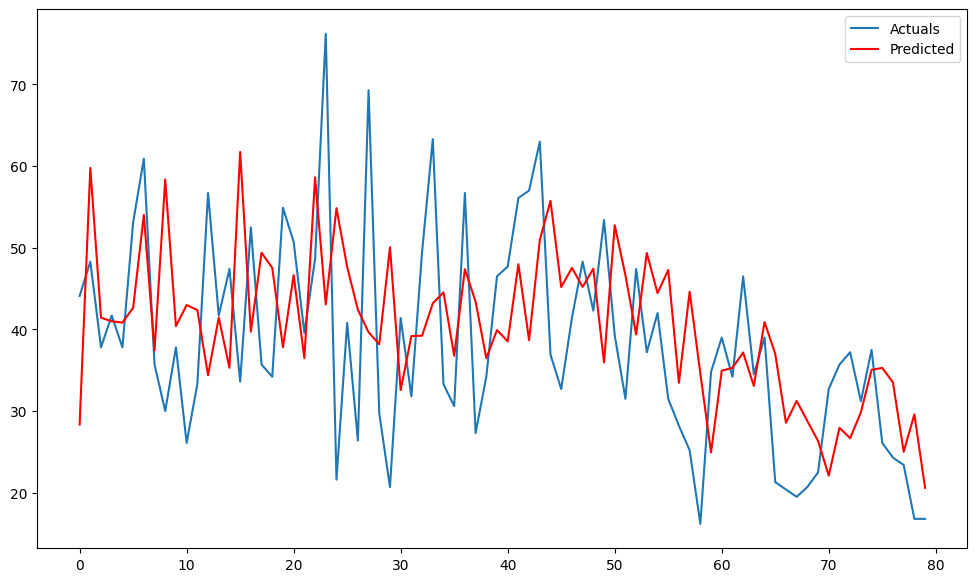

In [42]:
history = [x for x in train_log]
predictions = list()
predict_log=list()
for t in range(len(test_log)):
    model = sm.tsa.SARIMAX(history, order=my_order, seasonal_order=my_seasonal_order,enforce_stationarity=False,enforce_invertibility=False)
    model_fit = model.fit(disp=0)
    output = model_fit.forecast()
    predict_log.append(output[0])
    yhat = 10**output[0]
    predictions.append(yhat)
    obs = test_log[t]
    history.append(obs)
   # print('predicted=%f, expected=%f' % (output[0], obs))
#error = math.sqrt(mean_squared_error(test_log, predict_log))
#print('Test rmse: %.3f' % error)
# plot
figsize=(12, 7)
plt.figure(figsize=figsize)
pyplot.plot(test,label='Actuals')
pyplot.plot(predictions, color='red',label='Predicted')
pyplot.legend(loc='upper right')
pyplot.show()

In [43]:
df_preds = df[-80:]
df_preds['Predicted_Consumption'] = predictions

In [44]:
import plotly.graph_objects as go
import plotly.offline as py

In [45]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df_preds['Date'], y=df_preds['Total_Consumption'],
                    mode='lines',
                    name='lines'))
fig.add_trace(go.Scatter(x=df_preds['Date'], y=df_preds['Predicted_Consumption'],
                    mode='lines',
                    name='lines'))

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'mode': 'lines',
              'name': 'lines',
              'type': 'scatter',
              'x': array(['2021-05-09T00:00:00.000000000', '2021-05-10T00:00:00.000000000',
                          '2021-05-11T00:00:00.000000000', '2021-05-13T00:00:00.000000000',
                          '2021-05-14T00:00:00.000000000', '2021-05-15T00:00:00.000000000',
                          '2021-05-16T00:00:00.000000000', '2021-05-17T00:00:00.000000000',
                          '2021-05-18T00:00:00.000000000', '2021-05-19T00:00:00.000000000',
                          '2021-05-20T00:00:00.000000000', '2021-05-21T00:00:00.000000000',
                          '2021-05-22T00:00:00.000000000', '2021-05-23T00:00:00.000000000',
                          '2021-05-24T00:00:00.000000000', '2021-05-25T00:00:00.000000000',
                          '2021-05-26T00:00:00.000000000', '2021-05-27T00:00:00.000000000',
                          '2021-05-28T00:00:00.000000000', '2021-05-29T00:00:00.000000000',
                          '2021-05-30T00:00:00.000000000', '2021-05-31T00:00:00.000000000',
                          '2021-06-01T00:00:00.000000000', '2021-06-02T00:00:00.000000000',
                          '2021-06-03T00:00:00.000000000', '2021-06-04T00:00:00.000000000',
                          '2021-06-05T00:00:00.000000000', '2021-06-06T00:00:00.000000000',
                          '2021-06-07T00:00:00.000000000', '2021-06-08T00:00:00.000000000',
                          '2021-06-09T00:00:00.000000000', '2021-06-10T00:00:00.000000000',
                          '2021-06-11T00:00:00.000000000', '2021-06-13T00:00:00.000000000',
                          '2021-06-14T00:00:00.000000000', '2021-06-15T00:00:00.000000000',
                          '2021-06-16T00:00:00.000000000', '2021-06-17T00:00:00.000000000',
                          '2021-06-18T00:00:00.000000000', '2021-06-19T00:00:00.000000000',
                          '2021-06-20T00:00:00.000000000', '2021-06-21T00:00:00.000000000',
                          '2021-06-22T00:00:00.000000000', '2021-06-23T00:00:00.000000000',
                          '2021-06-24T00:00:00.000000000', '2021-06-25T00:00:00.000000000',
                          '2021-06-26T00:00:00.000000000', '2021-06-27T00:00:00.000000000',
                          '2021-06-28T00:00:00.000000000', '2021-06-29T00:00:00.000000000',
                          '2021-06-30T00:00:00.000000000', '2021-07-01T00:00:00.000000000',
                          '2021-07-02T00:00:00.000000000', '2021-07-03T00:00:00.000000000',
                          '2021-07-04T00:00:00.000000000', '2021-07-05T00:00:00.000000000',
                          '2021-07-06T00:00:00.000000000', '2021-07-07T00:00:00.000000000',
                          '2021-07-08T00:00:00.000000000', '2021-07-09T00:00:00.000000000',
                          '2021-07-10T00:00:00.000000000', '2021-07-11T00:00:00.000000000',
                          '2021-07-13T00:00:00.000000000', '2021-07-14T00:00:00.000000000',
                          '2021-07-15T00:00:00.000000000', '2021-07-16T00:00:00.000000000',
                          '2021-07-17T00:00:00.000000000', '2021-07-18T00:00:00.000000000',
                          '2021-07-19T00:00:00.000000000', '2021-07-20T00:00:00.000000000',
                          '2021-07-21T00:00:00.000000000', '2021-07-22T00:00:00.000000000',
                          '2021-07-23T00:00:00.000000000', '2021-07-24T00:00:00.000000000',
                          '2021-07-25T00:00:00.000000000', '2021-07-26T00:00:00.000000000',
                          '2021-07-27T00:00:00.000000000', '2021-07-28T00:00:00.000000000',
                          '2021-07-29T00:00:00.000000000', '2021-07-30T00:00:00.000000000'],
                         dtype='datetime64[ns]'),
              'y': {'bdata': ('zMzMzMwMRkBmZmZmZiZIQGZmZmZm5k' ... 'ZmZjdAzMzMzMzMMEDMzMzMzMwwQA=='),
                    'dtype': 'f8'}},
             {'mode': 'lin

In [46]:
new_dates = pd.date_range(start='2021/07/31', end='2021/09/30')

In [47]:
train = df.Total_Consumption.values

my_order = (1, 1, 1)
my_seasonal_order = (1, 1, 1, 62)

model = sm.tsa.SARIMAX(train, order=my_order, seasonal_order=my_seasonal_order,enforce_stationarity=False,enforce_invertibility=False)
model_fit = model.fit()
output = model_fit.forecast(62)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            5     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.67496D+00    |proj g|=  1.97701D-01


 This problem is unconstrained.



At iterate    5    f=  1.61216D+00    |proj g|=  8.73750D-03

At iterate   10    f=  1.60169D+00    |proj g|=  3.44777D-02

At iterate   15    f=  1.59587D+00    |proj g|=  4.17834D-03

At iterate   20    f=  1.59576D+00    |proj g|=  3.13973D-06

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    5     20     23      1     0     0   3.140D-06   1.596D+00
  F =   1.5957639479224892     

CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL            


In [48]:
import numpy as np
listofzeros = [np.nan] * 62

In [49]:
data_new = {'Date':new_dates,
            'Total_Consumption':listofzeros,
            'Predicted_Consumption':output}

df_new_preds = pd.DataFrame(data_new)

In [50]:
df_all = pd.concat([df_preds, df_new_preds], ignore_index=True)

In [51]:
df_all.head(2)

,Date,Total_Consumption,Predicted_Consumption
0,2021-05-09,44.1,28.343739
1,2021-05-10,48.3,59.779650


In [52]:
df_all['MAE'] = df_all['Total_Consumption'] - df_all['Predicted_Consumption']

### Threshold: 5

In [53]:
df_anoms = df_all[df_all['MAE'] >= 5]
df_anoms.reset_index(drop=True, inplace=True)

In [54]:
df_anoms.tail(2)

,Date,Total_Consumption,Predicted_Consumption,MAE
23,2021-07-22,35.7,27.940801,7.759199
24,2021-07-23,37.2,26.677227,10.522773


In [55]:
df_anoms['extra_MAE'] = df_anoms['MAE'] - 5

In [56]:
df_anoms['extra_MAE_cost'] = df_anoms['extra_MAE']*9

In [57]:
df_anoms.groupby(df_anoms['Date'].dt.month)['extra_MAE_cost'].sum()

Date
5     561.311758
6    1107.052568
7     234.802557
Name: extra_MAE_cost, dtype: float64

In [58]:
df_all.groupby(df_all['Date'].dt.month)['Total_Consumption'].sum().reset_index()['Total_Consumption']*7

0    6535.2
1    8862.0
2    6113.1
3       0.0
4       0.0
Name: Total_Consumption, dtype: float64

In [59]:
180/2300 # 8-15%

0.0782608695652174

### Threshold: 10

In [60]:
df_anoms = df_all[df_all['MAE'] >= 10]
df_anoms.reset_index(drop=True, inplace=True)

In [61]:
df_anoms.tail(2)

,Date,Total_Consumption,Predicted_Consumption,MAE
13,2021-07-21,32.7,22.096927,10.603073
14,2021-07-23,37.2,26.677227,10.522773


In [62]:
df_anoms['extra_MAE'] = df_anoms['MAE'] - 10

In [63]:
df_anoms['extra_MAE_cost'] = df_anoms['extra_MAE']*9

In [64]:
df_anoms.groupby(df_anoms['Date'].dt.month)['extra_MAE_cost'].sum()

Date
5    274.413079
6    638.775062
7     10.132619
Name: extra_MAE_cost, dtype: float64

In [65]:
df_all.groupby(df_all['Date'].dt.month)['Total_Consumption'].sum().reset_index()['Total_Consumption']*7

0    6535.2
1    8862.0
2    6113.1
3       0.0
4       0.0
Name: Total_Consumption, dtype: float64

In [66]:
638/8862 # 8-15%

0.0719927781539156

### Threshold: 12

In [67]:
df_anoms = df_all[df_all['MAE'] >= 12]
df_anoms.reset_index(drop=True, inplace=True)

In [68]:
df_anoms.tail(2)

,Date,Total_Consumption,Predicted_Consumption,MAE
9,2021-06-23,63.0,50.950656,12.049344
10,2021-06-29,53.4,35.954989,17.445011


In [69]:
df_anoms['extra_MAE'] = df_anoms['MAE'] - 12

In [70]:
df_anoms['extra_MAE_cost'] = df_anoms['extra_MAE']*9

In [71]:
df_anoms.groupby(df_anoms['Date'].dt.month)['extra_MAE_cost'].sum()

Date
5    180.287871
6    528.342853
Name: extra_MAE_cost, dtype: float64

In [72]:
df_all.groupby(df_all['Date'].dt.month)['Total_Consumption'].sum().reset_index()['Total_Consumption']*7

0    6535.2
1    8862.0
2    6113.1
3       0.0
4       0.0
Name: Total_Consumption, dtype: float64

In [73]:
180/2300 # 8-15%

0.0782608695652174